# AI CCTV Anomaly Detection —



## Step 1 — Upload the project ZIP and prepare the project



In [1]:
import os, sys, zipfile, shutil, subprocess, time, json, glob, pathlib
from google.colab import files
from IPython.display import display, Image, HTML
import pandas as pd

print("Python:", sys.version.split()[0])
gpu = subprocess.run(["nvidia-smi"], capture_output=True, text=True)
print(gpu.stdout[:1200] if gpu.returncode == 0 else "No GPU detected. CPU training can be much slower.")

possible_zips = [
    "/content/AI_CCTV_Final_Project.zip",
    "/content/ai-cctv-anomaly-detection.zip",
    "/content/ai-cctv-anomaly-detection(1).zip",
]
zip_path = next((p for p in possible_zips if os.path.isfile(p)), None)
if zip_path is None:
    print("Choose your complete project ZIP in the file picker.")
    uploaded = files.upload()
    if not uploaded:
        raise RuntimeError("No project ZIP was uploaded.")
    uploaded_name = next(iter(uploaded))
    zip_path = os.path.join("/content", uploaded_name)

if not zipfile.is_zipfile(zip_path):
    raise ValueError(f"The uploaded file is not a valid ZIP: {zip_path}")

extract_dir = "/content/ai_cctv_one_click_project"
if os.path.isdir(extract_dir):
    shutil.rmtree(extract_dir)
os.makedirs(extract_dir, exist_ok=True)
with zipfile.ZipFile(zip_path) as zf:
    zf.extractall(extract_dir)

candidates = []
for root, dirs, filenames in os.walk(extract_dir):
    dirs[:] = [d for d in dirs if d not in {".git", "__MACOSX", "__pycache__", ".pytest_cache"}]
    if "app.py" in filenames and "requirements.txt" in filenames and os.path.isfile(os.path.join(root, "src", "train.py")):
        candidates.append(root)
if not candidates:
    raise FileNotFoundError("Could not find the complete project (app.py, requirements.txt, src/train.py). Upload the full project ZIP, not results.zip.")

PROJECT = max(candidates, key=lambda p: os.path.isfile(os.path.join(p, "models", "autoencoder.pt")))
os.chdir(PROJECT)
print("\nProject folder:", PROJECT)
print("Saved model found:", os.path.isfile(os.path.join(PROJECT, "models", "autoencoder.pt")))
print("Saved threshold found:", os.path.isfile(os.path.join(PROJECT, "models", "threshold.json")))

ModuleNotFoundError: No module named 'google'

## Step 2 — Install project dependencies

This runs automatically during **Run all**.

In [ ]:
os.chdir(PROJECT)
install = subprocess.run(
    [sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"],
    text=True, capture_output=True
)
if install.returncode != 0:
    print(install.stdout[-3000:])
    print(install.stderr[-8000:])
    raise RuntimeError("Dependency installation failed. Read the error above.")
print("Dependencies installed successfully.")

Dependencies installed successfully.


## Step 3 — Download the public dataset if it is missing

The notebook uses KaggleHub for the public dataset, so you do **not** need to upload `kaggle.json`. If the project ZIP already contains dataset media, this step skips downloading.

In [ ]:
os.chdir(PROJECT)
DATASET_DIR = os.path.join(PROJECT, "data", "raw", "cctv-exam-monitor-dataset")
IMAGE_EXTS = (".jpg", ".jpeg", ".png", ".bmp", ".webp")
VIDEO_EXTS = (".mp4", ".avi", ".mov", ".mkv", ".m4v")

def count_media(folder):
    count = 0
    if os.path.isdir(folder):
        for root, dirs, names in os.walk(folder):
            count += sum(n.lower().endswith(IMAGE_EXTS + VIDEO_EXTS) for n in names)
    return count

media_before = count_media(DATASET_DIR)
if media_before == 0:
    print("No dataset images/videos found inside the project ZIP. Downloading the public Kaggle dataset...")
    kh = subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kagglehub"], text=True, capture_output=True)
    if kh.returncode != 0:
        print(kh.stderr[-5000:])
        raise RuntimeError("Could not install kagglehub.")
    import kagglehub
    downloaded_path = kagglehub.dataset_download("cctvdataset/cctv-exam-monitor-dataset")
    print("KaggleHub download location:", downloaded_path)
    if os.path.exists(DATASET_DIR):
        shutil.rmtree(DATASET_DIR)
    os.makedirs(os.path.dirname(DATASET_DIR), exist_ok=True)
    shutil.copytree(downloaded_path, DATASET_DIR)
else:
    print("Dataset media already included; download skipped.")

media_count = count_media(DATASET_DIR)
print("Dataset folder:", DATASET_DIR)
print("Image/video files found:", media_count)
if media_count == 0:
    raise RuntimeError("Dataset download finished but no image/video files were found. Check Kaggle access and the dataset layout.")

No dataset images/videos found inside the project ZIP. Downloading the public Kaggle dataset...


100%|██████████| 598M/598M [00:06<00:00, 95.8MB/s]

Extracting files...


KaggleHub download location: /root/.cache/kagglehub/datasets/cctvdataset/cctv-exam-monitor-dataset/versions/1
Dataset folder: /content/ai_cctv_one_click_project/ai-cctv-anomaly-detection/data/raw/cctv-exam-monitor-dataset
Image/video files found: 8156


## Step 4 — Inspect the dataset and configure training

The inspector output helps identify labels. This project may have unlabeled images, so the notebook does not invent supervised evaluation scores.

In [ ]:
os.chdir(PROJECT)
inspect = subprocess.run([sys.executable, "-m", "src.dataset_inspector"], text=True, capture_output=True)
print(inspect.stdout[-10000:])
if inspect.stderr:
    print(inspect.stderr[-3000:])

import yaml
config_path = os.path.join(PROJECT, "config.yaml")
if not os.path.isfile(config_path):
    raise FileNotFoundError("config.yaml is missing from the project ZIP.")
config_backup = config_path + ".one_click_backup"
if not os.path.exists(config_backup):
    shutil.copy2(config_path, config_backup)
cfg = yaml.safe_load(open(config_path))
cfg.setdefault("paths", {})
cfg.setdefault("data", {})
cfg.setdefault("training", {})
cfg["paths"]["dataset_root"] = "data/raw/cctv-exam-monitor-dataset"
cfg["data"]["label_mode"] = "auto"
cfg["data"]["normal_class_names"] = ["normal"]
cfg["data"]["abnormal_class_names"] = ["abnormal", "anomaly", "anomalous"]
cfg["data"]["assume_unlabeled_normal"] = True
cfg["training"]["epochs"] = int(cfg["training"].get("epochs", 30))
yaml.safe_dump(cfg, open(config_path, "w"), sort_keys=False)
print("\nConfiguration ready. Training epochs:", cfg["training"]["epochs"])

DATASET INSPECTION REPORT
Root           : /content/ai_cctv_one_click_project/ai-cctv-anomaly-detection/data/raw/cctv-exam-monitor-dataset
Total files    : 8156   videos: 0   images: 8156
Extensions     : {'.jpg': 8156}
Top-level items: ['CCTV-Exam -Monitor -Dataset']

Folders containing media (direct counts):
  CCTV-Exam -Monitor -Dataset/test                        {'images': 220}
  CCTV-Exam -Monitor -Dataset/train                       {'images': 7734}
  CCTV-Exam -Monitor -Dataset/valid                       {'images': 202}

Suggested data.label_mode: none
  reason: No folder names match your configured normal/abnormal names and no usable label CSV was recognised. Use normal-only training + qualitative analysis, or create a labels CSV.

NEXT: edit config.yaml (label_mode, class names, labels_csv) to match what you see above.
Report saved to /content/ai_cctv_one_click_project/ai-cctv-anomaly-detection/outputs/dataset_report.json


Configuration ready. Training epochs: 30


## Step 5 — Train the model if needed

If the project ZIP already contains a trained model, it is reused. Otherwise the model trains on the downloaded dataset. Training can take a while; do not stop the cell just because it is taking time.

In [ ]:
os.chdir(PROJECT)
MODEL_PATH = os.path.join(PROJECT, "models", "autoencoder.pt")
THRESHOLD_PATH = os.path.join(PROJECT, "models", "threshold.json")

def run_live(command, label):
    print(f"\n--- {label} ---", flush=True)
    proc = subprocess.Popen(command, cwd=PROJECT, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
    tail = []
    for line in proc.stdout:
        print(line, end="", flush=True)
        tail.append(line)
        if len(tail) > 100:
            tail.pop(0)
    rc = proc.wait()
    if rc != 0:
        print("Last output lines:")
        print("".join(tail[-40:]))
    return rc

if not os.path.isfile(MODEL_PATH):
    rc = run_live([sys.executable, "-u", "-m", "src.train"], "Model training")
    if rc != 0:
        raise RuntimeError("Model training failed. Read the error output above.")
else:
    print("Existing trained model found; training skipped.")

if not os.path.isfile(MODEL_PATH):
    raise FileNotFoundError("Training finished but models/autoencoder.pt was not created.")
print("Model ready:", MODEL_PATH)

Existing trained model found; training skipped.
Model ready: /content/ai_cctv_one_click_project/ai-cctv-anomaly-detection/models/autoencoder.pt


## Step 6 — Calibrate threshold and display training graphs

In [ ]:
os.chdir(PROJECT)
if not os.path.isfile(THRESHOLD_PATH):
    rc = run_live([sys.executable, "-u", "-m", "src.calibrate_threshold"], "Threshold calibration")
    if rc != 0:
        print("Threshold calibration failed; see the log above. The notebook will continue to show available outputs.")
else:
    print("Existing threshold found; calibration skipped.")

print("\nThreshold file:")
if os.path.isfile(THRESHOLD_PATH):
    print(json.dumps(json.load(open(THRESHOLD_PATH)), indent=2))
else:
    print("Threshold file not available.")

history_path = os.path.join(PROJECT, "outputs", "training_history.csv")
if os.path.isfile(history_path):
    display(pd.read_csv(history_path).tail(10))
else:
    print("Training history CSV not found.")
for name in ["training_curve.png", "reconstruction_samples.png", "threshold_calibration.png"]:
    p = os.path.join(PROJECT, "outputs", name)
    if os.path.isfile(p):
        print(name)
        display(Image(filename=p))
    else:
        print("Graph not available:", name)

Existing threshold found; calibration skipped.

Threshold file:
{
  "threshold": 0.02985895796492696,
  "method": "percentile",
  "percentile": 99.0,
  "std_k": 3.0,
  "score_method": "mse",
  "topk_fraction": 0.02,
  "smoothing_window": 5,
  "calibrated_on": "validation split only",
  "n_val_frames_scored": 7734,
  "n_val_normal_used": 7734,
  "val_normal_score_stats": {
    "mean": 0.01669798271228233,
    "std": 0.004339465712654354,
    "median": 0.016607119515538216,
    "p95": 0.02371978077106177,
    "p99": 0.02985895796492696,
    "max": 0.04030126929283142
  },
  "synthetic_fixture": false,
  "created": "2026-10-24T12:45:52"
}
Training history CSV not found.
Graph not available: training_curve.png
Graph not available: reconstruction_samples.png
Graph not available: threshold_calibration.png


## Step 7 — Evaluate and show available evaluation graphs

Metrics are shown only if the project can calculate them from available labels. Unlabeled data cannot support trustworthy accuracy, precision, recall, F1, ROC-AUC, or PR-AUC claims.


--- Evaluation ---
14:19:15 | INFO | Label mode in use: none
14:19:15 | INFO | Manifest built: 8156 frames.
14:19:18 | WARNING | Supervised metrics (accuracy/precision/recall/F1/confusion matrix) were NOT computed: the test split has no frames of BOTH labelled classes, and fabricating ground truth is not valid. Only score statistics and qualitative results are reported.
14:19:18 | INFO | Evaluation saved to /content/ai_cctv_one_click_project/ai-cctv-anomaly-detection/outputs/evaluation

Evaluation note: Supervised metrics (accuracy/precision/recall/F1/confusion matrix) were NOT computed: the test split has no frames of BOTH labelled classes, and fabricating ground truth is not valid. Only score statistics and qualitative results are reported.
{
  "threshold": 0.02985895796492696,
  "threshold_method": "percentile",
  "n_test_frames": 220,
  "n_labeled": 0,
  "n_unlabeled": 220,
  "synthetic_fixture": false,
  "overall_flag_rate": 0.0,
  "note": "Supervised metrics (accuracy/precision/

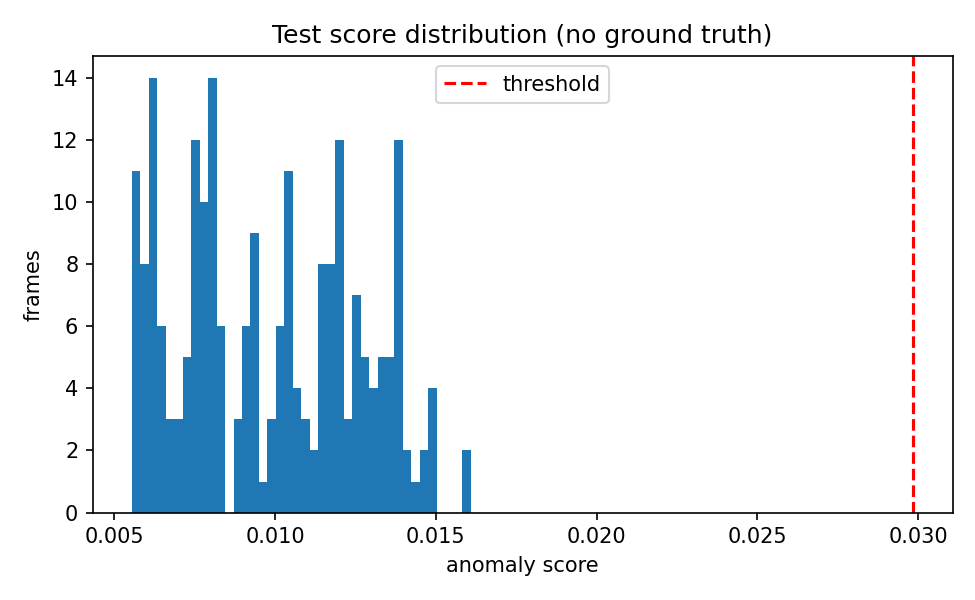

highest_scoring_frames.png


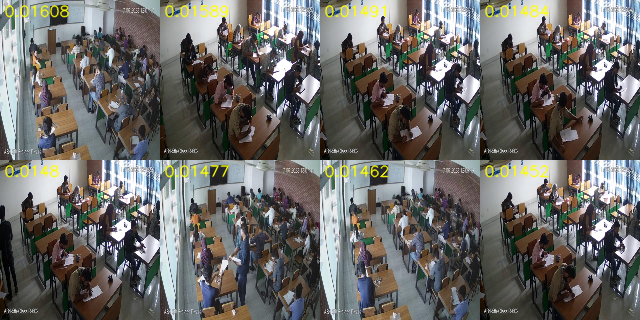

In [ ]:
os.chdir(PROJECT)
rc = run_live([sys.executable, "-u", "-m", "src.evaluate"], "Evaluation")
if rc != 0:
    print("Evaluation could not complete on this dataset; packaging the outputs that are available.")

metrics_path = os.path.join(PROJECT, "outputs", "evaluation", "metrics.json")
if os.path.isfile(metrics_path):
    metrics = json.load(open(metrics_path))
    print("\nEvaluation note:", metrics.get("note", ""))
    print(json.dumps(metrics, indent=2)[:8000])
else:
    print("No evaluation metrics file was produced.")

for name in ["confusion_matrix.png", "roc_pr_curves.png", "score_distribution.png", "highest_scoring_frames.png"]:
    p = os.path.join(PROJECT, "outputs", "evaluation", name)
    if os.path.isfile(p):
        print(name)
        display(Image(filename=p))
    else:
        print("Evaluation graph unavailable:", name)

## Step 8 — Run inference if the dataset contains a video

If the downloaded dataset contains videos, the notebook runs inference on the first one. If it contains images only, this step safely skips video inference.

In [ ]:
os.chdir(PROJECT)
videos = []
for root, dirs, names in os.walk(DATASET_DIR):
    videos.extend(os.path.join(root, n) for n in names if n.lower().endswith(VIDEO_EXTS))
print("Videos found in dataset:", len(videos))
if videos:
    video_path = videos[0]
    print("Running inference on:", video_path)
    rc = run_live([sys.executable, "-u", "-m", "src.video_processor", "--video", video_path], "Video inference")
    if rc != 0:
        print("Video inference failed; other outputs will still be packaged.")
else:
    print("No video files were included in the dataset. Video inference skipped; the dashboard can still accept a video upload.")

Videos found in dataset: 0
No video files were included in the dataset. Video inference skipped; the dashboard can still accept a video upload.


## Step 9 — Create and download `results.zip`

The ZIP contains the trained model, threshold, configuration, logs, plots, evaluation outputs, and inference results that exist at this point.

In [ ]:
os.chdir(PROJECT)
RESULTS_ZIP = "/content/results.zip"
include_items = ["models", "outputs", "config.yaml"]
with zipfile.ZipFile(RESULTS_ZIP, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    for item in include_items:
        full = os.path.join(PROJECT, item)
        if os.path.isfile(full):
            zf.write(full, arcname=item)
        elif os.path.isdir(full):
            for root, dirs, names in os.walk(full):
                for name in names:
                    f = os.path.join(root, name)
                    zf.write(f, arcname=os.path.relpath(f, PROJECT))
print("Created:", RESULTS_ZIP, "| Size MB:", round(os.path.getsize(RESULTS_ZIP)/(1024*1024), 2))
files.download(RESULTS_ZIP)

Created: /content/results.zip | Size MB: 20.74


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Step 10 — Launch the Streamlit dashboard

The final cell starts Streamlit in the background and prints a Colab proxy URL. Keep the Colab runtime connected while using the dashboard.

In [ ]:
os.chdir(PROJECT)
# Terminate older Streamlit processes without killing the current notebook kernel.
try:
    import psutil
    for p in psutil.process_iter(["pid", "cmdline"]):
        try:
            cmd = " ".join(p.info.get("cmdline") or [])
            if p.info["pid"] != os.getpid() and "streamlit" in cmd and "run" in cmd and "app.py" in cmd:
                p.terminate()
        except (psutil.NoSuchProcess, psutil.AccessDenied):
            pass
except Exception:
    pass

log_path = "/tmp/streamlit.log"
log_handle = open(log_path, "w")
streamlit_proc = subprocess.Popen(
    [sys.executable, "-m", "streamlit", "run", "app.py",
     "--server.port", "8501",
     "--server.address", "0.0.0.0",
     "--server.enableCORS", "false",
     "--server.enableXsrfProtection", "false"],
    cwd=PROJECT, stdout=log_handle, stderr=subprocess.STDOUT, start_new_session=True
)
time.sleep(8)
print(open(log_path, errors="ignore").read()[-5000:])
from google.colab.output import eval_js
try:
    dashboard_url = eval_js("google.colab.kernel.proxyPort(8501)")
    print("\nDASHBOARD URL — click to open:")
    print(dashboard_url)
    display(HTML(f'<a href="{dashboard_url}" target="_blank">Open AI CCTV Dashboard</a>'))
except Exception as e:
    print("Could not generate the dashboard proxy URL:", repr(e))
    print("Check the Streamlit log above.")



2026-10-24 14:19:27.297 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://136.85.176.141:8501



DASHBOARD URL — click to open:
https://8501-gpu-t4-s-kkb-usw4b1-3d41d2fman2jb-b.us-west4-1.prod.colab.dev


## If the dashboard link fails

Run this troubleshooting cell only if the dashboard URL says “Site can’t be reached.” It prints the Streamlit log and a fresh proxy URL.

In [ ]:
print(open("/tmp/streamlit.log", errors="ignore").read()[-8000:] if os.path.isfile("/tmp/streamlit.log") else "No Streamlit log found.")
try:
    print("\nFresh dashboard URL:")
    print(eval_js("google.colab.kernel.proxyPort(8501)"))
except Exception as e:
    print("Proxy URL error:", repr(e))



2026-10-24 14:19:27.297 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://136.85.176.141:8501



Fresh dashboard URL:
https://8501-gpu-t4-s-kkb-usw4b1-3d41d2fman2jb-b.us-west4-1.prod.colab.dev
